Final Mean Estimation: Integral = 0.3266
--------------------------------------------------
P1(x) = x**2 - x + 1/2
P2(x) = -x**2 + x + 1/2
--------------------------------------------------
Area Integral  = Integral(-2*x**2 + 2*x, (x, 0, 1))
--------------------------------------------------
Exact Area (fraction) = 1/3
Exact Area (decimal)  = 0.3333333333333333
Monte Carlo Integration method experiment = 0.3266


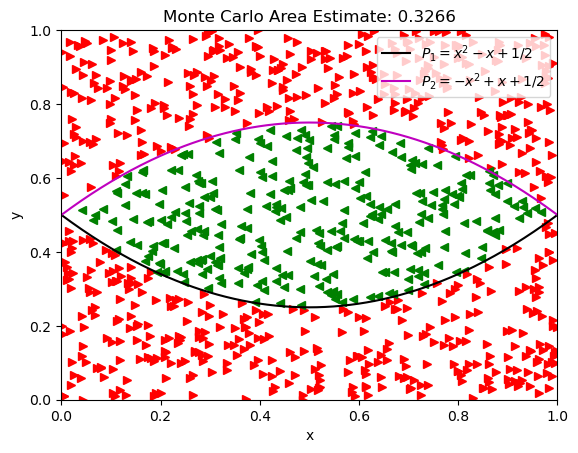

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

#Set random seed for reproducibility
np.random.seed(0)

#Function to generate a random number in the interval [a, b]
def random(a, b):
    return a + (b - a) * np.random.random()

#Definition of the two parabolas P1 and P2
def P1(x):
    return x**2 - x + 1/2

def P2(x):
    return -x**2 + x + 1/2
    
# 1. Monte Carlo integration to estimate the enclosed area between parabolas P1 and P2
# Number of random points to generate
n = 1000 # n = 10^3
# Number of loops
num = 10 

estimates = []
#We execute the experiment 10 times
for i in range(num):
    #Initialize counters for total points and points inside the region of interest
    tot = cntIn = 0
    #Monte Carlo method for numerical integration
    for p_iter in range(n):
        #Generate a random point (p_x, p_y) in [0, 1] x [0, 1]
        p_x, p_y = random(0, 1), random(0, 1)

        # We calculate the values of the parabolas at point p_x
        y_P1 = P1(p_x)
        y_P2 = P2(p_x)

        tot += 1  # Increment total points

        # Check if the random point is inside the region defined by the parabolas
        if y_P1 <= p_y <= y_P2:
            cntIn += 1  # Increment points inside counter
            #We only plot the sample points from the first experiment (i == 0) as required
            if i == 0:
                plt.plot(p_x, p_y, 'g<')  # Plot in red if inside
        else:
            if i == 0:    # We only plot the sample points from the first experiment (trial == 0) as required
                plt.plot(p_x, p_y, 'r>')  # Plot in green if outside
                
    # Estimate the integral for this experiment: Area = Box_Area * (cntIn / tot), where Box_Area = width*height = [1-0]*[1-0] = 1
    integral_exp = (cntIn/tot)
    estimates.append(integral_exp)

# We calculate the average value of all results (final estimation)
Integral = sum(estimates) / len(estimates)
print("Final Mean Estimation: Integral =", Integral)

# 2. Matplotlib Visualization: Parabolas and Monte Carlo points from the first experiment
x = np.linspace(0, 1, 300)
plt.plot(x, P1(x),'k', label=r'$P_1 = x^2 - x + 1/2$')
plt.plot(x, P2(x),'m', label=r'$P_2 = -x^2 + x + 1/2$')

# Plot the points and the result
plt.xlim(0,1)
plt.ylim(0,1)
plt.xlabel('x')
plt.ylabel('y')
plt.legend(loc='upper right')
plt.title('Monte Carlo Area Estimate: %.4f' % (Integral))

# 3.
print('-' * 50)
# We define the symbolic variable x
x = sp.Symbol('x')

# We define the formulas of the two parabolas
P1 = x**2 - x + sp.Rational(1, 2)
P2 = -x**2 + x + sp.Rational(1, 2)

# We print the expressions of the two parabolas
print('P1(x) =', P1)
print('P2(x) =', P2)
print('-' * 50)

# We define the integral of the enclosed region between the curves from 0 to 1
# sp.Integral displays the mathematical formula unevaluated
integral_formula = sp.Integral(P2 - P1, (x, 0, 1))
print('Area Integral  =', integral_formula)

# We compute the exact analytical integral directly using sp.integrate
exact_area = sp.integrate(P2 - P1, (x, 0, 1))

print('-' * 50)
# We print the exact calculated area
print('Exact Area (fraction) =', exact_area)
print('Exact Area (decimal)  =', float(exact_area))
print('Monte Carlo Integration method experiment =', Integral)